In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 13 — Ablasi koordinasi

**Tujuan:** menguji apakah fitur koordinasi menambah nilai di atas `M_behav` (RQ5), tahap pengembangan.
Hasil nol adalah hasil yang sah, dan fitur tidak diubah untuk mengejar hasil positif.

In [3]:
import json

import pandas as pd

from ghremoval.analysis import bootstrap_gain, coordination_ladder
from ghremoval.config import load_context
from ghremoval.quality import Checks
from ghremoval.report import save_table
from ghremoval.runlog import RunLog
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("13_coordination_ablation", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
best = json.loads((ctx.paths.results / "best_params.json").read_text())

In [4]:
result = coordination_ladder(ctx, "dev", best)
table = pd.DataFrame(result["rows"])
save_table(table, "tab_coord_ablation", "Coordination feature ablation, development stage (observed label)")
table[["model", "arm", "n", "n_pos", "ap_all", "ap_5-19", "ap_20+", "n_pos_in_blocks"]]

,model,arm,n,n_pos,ap_all,ap_5-19,ap_20+,n_pos_in_blocks
0,M_behav,F2_forward_new_accounts,22095,560,0.203824,0.184092,0.429713,554
1,M_proxy,F2_forward_new_accounts,22095,560,0.214555,0.189881,0.452445,554
2,M_coord,F2_forward_new_accounts,22095,560,0.200040,0.176755,0.421785,554
3,M_behav,F3_forward_batch_excluded,19102,421,0.168674,0.152344,0.340737,416
4,M_proxy,F3_forward_batch_excluded,19102,421,0.167060,0.145941,0.385853,416
5,M_coord,F3_forward_batch_excluded,19102,421,0.160427,0.140544,0.356843,416


## Selisih berpasangan

,comparison,delta,low,high,p_one_sided,n_clusters_with_pos
0,M_proxy - M_behav | F2_forward_new_accounts,0.005789,-0.017202,0.031896,0.3600,364.0
1,M_proxy - M_behav | F3_forward_batch_excluded,-0.006403,-0.022302,0.007562,0.8095,276.0
2,M_coord - M_behav | F2_forward_new_accounts,-0.007337,-0.035099,0.027692,0.6585,364.0
3,M_coord - M_behav | F3_forward_batch_excluded,-0.011799,-0.034686,0.012197,0.7880,276.0
4,M_coord - M_proxy | F2_forward_new_accounts,-0.013126,-0.025976,0.006108,0.9095,364.0
5,M_coord - M_proxy | F3_forward_batch_excluded,-0.005397,-0.019605,0.014659,0.6745,276.0


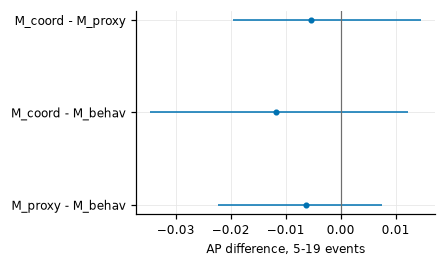

In [5]:
data, scores = result["data"], result["scores"]
pairs = {"M_proxy - M_behav": ("M_proxy", "M_behav"), "M_coord - M_behav": ("M_coord", "M_behav"), "M_coord - M_proxy": ("M_coord", "M_proxy")}
gains = {}
for name, (a, b) in pairs.items():
    for arm in ("F2_forward_new_accounts", "F3_forward_batch_excluded"):
        gains[f"{name} | {arm}"] = bootstrap_gain(ctx, data, scores[a], scores[b], arm, "5-19")
gain_table = pd.DataFrame(gains).T.reset_index(names="comparison")
(ctx.paths.results / "coord_dev.json").write_text(json.dumps(gains, indent=2, default=float) + "\n")
fig, ax = new_figure()
subset = gain_table[gain_table.comparison.str.contains("F3")]
ax.errorbar(subset["delta"].astype(float), range(len(subset)), xerr=[subset["delta"].astype(float) - subset["low"].astype(float), subset["high"].astype(float) - subset["delta"].astype(float)], fmt="o", ms=3, color="#0072B2", lw=1)
ax.set_yticks(range(len(subset))); ax.set_yticklabels([c.split(" | ")[0] for c in subset["comparison"]]); ax.axvline(0, color="#6E6E6E", lw=0.8)
ax.set_xlabel("AP difference, 5-19 events")
save_figure(fig, "fig_coord_ablation")
gain_table[["comparison", "delta", "low", "high", "p_one_sided", "n_clusters_with_pos"]]

## Ringkasan & cek

In [6]:
checks.add("Q17", "w3" not in set(data.test["week"].unique()), "tanpa w3")
checks.raise_if_failed()
print(run.finish(n_test=data.test.height))

[LULUS] Q17: tanpa w3
{'notebook': '13_coordination_ablation', 'finished_at_utc': '2026-11-10T12:00:40+00:00', 'git_commit': 'f04dbd3', 'duration_seconds': 94.2, 'counts': {'n_test': 22095}}
